# 01 - Veri Analizi: AI4I 2020 Predictive Maintenance

Aşama 1: modeli eğitmeden önce veri setini tanıyoruz. NumPy = sayısal işlemler
Pandas = tablo/veri analizi

## Kütüphaneler

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Geniş tabloların tüm sütunlarını gösteriyoruz.
pd.set_option("display.max_columns", None)

## Veri Setini Yükleme

In [2]:
# Notebook notebooks/ klasöründe çalışır; veri bir üst klasördeki data/ içindedir.
DATA_PATH = Path("../data/ai4i2020.csv")

# CSV dosyasını DataFrame olarak okuyoruz.
# Dosya UTF-8 BOM ile başladığı için "utf-8-sig" kullanıyoruz; aksi halde ilk sütun "\ufeffUDI" olur.
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

In [3]:
# İlk beş kaydı inceliyoruz. Her satır, bir ürünün tek bir ölçüm kaydıdır.
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Veri Yapısı

In [4]:
# (satır sayısı, sütun sayısı)
df.shape

(10000, 14)

In [5]:
# Gerçek sütun adları; kodda birebir bu yazımı kullanmalıyız.
df.columns.tolist()

['UDI',
 'Product ID',
 'Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Machine failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

In [6]:
# Her sütunun veri tipi. "object" metin demektir ve modelden önce sayıya çevrilmelidir.
df.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

## Eksik ve Tekrarlı Veriler

In [7]:
# Eksik değerleri sütun bazında kontrol ediyoruz.
df.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [8]:
# Tamamen aynı olan satırları sayıyoruz.
full_duplicates = df.duplicated().sum()

# Kimlik sütunları her satırda farklı olduğundan, onları çıkarıp tekrar kontrol ediyoruz.
duplicates_without_ids = df.drop(columns=["UDI", "Product ID"]).duplicated().sum()

pd.Series({
    "Tam tekrar eden satır": full_duplicates,
    "Kimlikler hariç tekrar eden satır": duplicates_without_ids,
    "Benzersiz UDI": df["UDI"].nunique(),
    "Benzersiz Product ID": df["Product ID"].nunique(),
})

Tam tekrar eden satır                    0
Kimlikler hariç tekrar eden satır        0
Benzersiz UDI                        10000
Benzersiz Product ID                 10000
dtype: int64

## İstatistiksel İnceleme

In [9]:
NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

# Sayısal özelliklerin ortalama, standart sapma, min, çeyreklik ve max değerleri.
df[NUMERIC_FEATURES].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0


## Type Dağılımı

In [10]:
# Ürün kalite tipi: L (düşük), M (orta), H (yüksek).
df["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [11]:
# Her tipteki arıza oranı (Machine failure sütununun ortalaması = 1'lerin oranı).
df.groupby("Type")["Machine failure"].mean().round(4)

Type
H    0.0209
L    0.0392
M    0.0277
Name: Machine failure, dtype: float64

## Sınıf Dağılımı

In [12]:
# Arızalı ve arızasız kayıtların sayısını ve oranını hesaplıyoruz.
counts = df["Machine failure"].value_counts().sort_index()
proportions = df["Machine failure"].value_counts(normalize=True).sort_index()

pd.DataFrame({"count": counts, "proportion": proportions.round(4)})

,count,proportion
Machine failure,,
0,9661,0.9661
1,339,0.0339


In [13]:
# Arızasız kayıt sayısının arızalı kayıt sayısına oranı: sınıflar ne kadar dengesiz?
imbalance_ratio = counts[0] / counts[1]
print(f"Dengesizlik oranı: {imbalance_ratio:.1f} : 1")

Dengesizlik oranı: 28.5 : 1


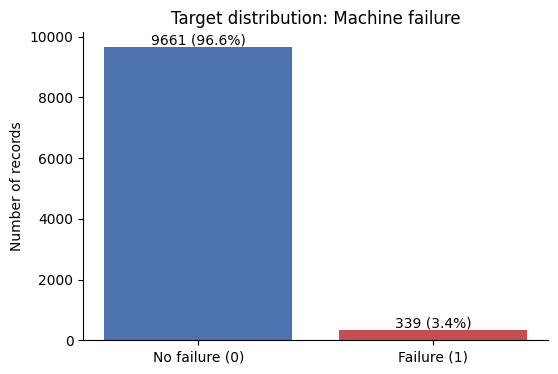

In [14]:
# Hedef sınıf dağılımını çubuk grafikle gösteriyoruz.
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["No failure (0)", "Failure (1)"], counts.values, color=["#4C72B0", "#C44E52"])

# Her çubuğun üstüne sayı ve yüzde yazıyoruz.
for bar, n, p in zip(bars, counts.values, proportions.values):
    ax.annotate(f"{n} ({p:.1%})", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")

ax.set_title("Target distribution: Machine failure")
ax.set_ylabel("Number of records")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Özellik ve Hedef Değişkenler

In [15]:
# Modelin girdi olarak kullanacağı özellikler (tahmin anında bilinen ölçümler).
FEATURES = ["Type"] + NUMERIC_FEATURES

# Tahmin edilecek ikili hedef: 0 = arıza yok, 1 = arıza var.
TARGET = "Machine failure"

# Kimlik sütunları: sadece kayıt numarası/ürün kodu, genellenebilir bilgi taşımaz.
ID_COLUMNS = ["UDI", "Product ID"]

# Arıza tipi etiketleri arızanın nedenini gösterir ve ancak arızadan SONRA bilinir.
# Modele verilirse cevabı "kopya çeker" (veri sızıntısı), bu yüzden girdi olamazlar.
FAILURE_TYPE_COLUMNS = ["TWF", "HDF", "PWF", "OSF", "RNF"]

EXCLUDED_COLUMNS = ID_COLUMNS + FAILURE_TYPE_COLUMNS

# Gruplar tüm sütunları eksiksiz ve çakışmasız kapsıyor mu?
assert set(FEATURES + [TARGET] + EXCLUDED_COLUMNS) == set(df.columns)

# Her sütunun rolünü tek tabloda gösteriyoruz.
roles = (
    [(c, "Özellik", "Evet") for c in FEATURES]
    + [(TARGET, "Hedef", "Tahmin edilen")]
    + [(c, "Kimlik", "Hayır") for c in ID_COLUMNS]
    + [(c, "Arıza tipi (sızıntı)", "Hayır") for c in FAILURE_TYPE_COLUMNS]
)
pd.DataFrame(roles, columns=["Sütun", "Rol", "Modele girer mi?"])

,Sütun,Rol,Modele girer mi?
0,Type,Özellik,Evet
1,Air temperature [K],Özellik,Evet
2,Process temperature [K],Özellik,Evet
3,Rotational speed [rpm],Özellik,Evet
4,Torque [Nm],Özellik,Evet
5,Tool wear [min],Özellik,Evet
6,Machine failure,Hedef,Tahmin edilen
7,UDI,Kimlik,Hayır
8,Product ID,Kimlik,Hayır
9,TWF,Arıza tipi (sızıntı),Hayır


In [16]:
# Sızıntı kanıtı: herhangi bir arıza tipi 1 olan satırlar, hedefle neredeyse birebir örtüşüyor.
any_failure_type = df[FAILURE_TYPE_COLUMNS].max(axis=1).rename("Any failure type")
pd.crosstab(any_failure_type, df[TARGET])

Machine failure,0,1
Any failure type,,
0,9643,9
1,18,330


In [17]:
# Product ID'nin ilk harfi Type ile aynı mı? Aynıysa ek bilgi taşımaz.
bool((df["Product ID"].str[0] == df["Type"]).all())

True